# TP Final · 01 · Datos y exploración

**Problema:** estimar la probabilidad de que un cliente de tarjeta de crédito caiga en mora el mes siguiente.

**Datos:** *Default of Credit Card Clients* (UCI Machine Learning Repository, licencia CC BY 4.0). 30.000 clientes de un banco de Taiwán, abril a septiembre de 2005.

Este notebook lee el CSV desde el volumen `landing`, prepara los datos, define la partición train/test y guarda la tabla Delta `tp_credit_default`, que usan los notebooks 02 y 03.

In [0]:
dbutils.widgets.text("student_id", "tfernandezaddoumie", "01 - Identificador")

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import pandas as pd

student_id = dbutils.widgets.get("student_id")
catalog = spark.sql("SELECT current_catalog()").first()[0]
schema = f"bigdata_{student_id}"
csv_path = f"/Volumes/{catalog}/{schema}/landing/tp_final/credit_default.csv"
table = f"{catalog}.{schema}.tp_credit_default"
print("CSV:  ", csv_path)
print("Tabla:", table)

CSV:   /Volumes/workspace/bigdata_tfernandezaddoumie/landing/tp_final/credit_default.csv
Tabla: workspace.bigdata_tfernandezaddoumie.tp_credit_default


## 1. Lectura del CSV

Se lee sin inferir tipos: todas las columnas llegan como texto. Los tipos se definen explícitamente en la preparación.

In [0]:
raw = spark.read.option("header", True).csv(csv_path)
print(f"{raw.count():,} filas · {len(raw.columns)} columnas")
raw.printSchema()
display(raw.limit(5))

30,000 filas · 25 columnas
root
 |-- ID: string (nullable = true)
 |-- LIMIT_BAL: string (nullable = true)
 |-- SEX: string (nullable = true)
 |-- EDUCATION: string (nullable = true)
 |-- MARRIAGE: string (nullable = true)
 |-- AGE: string (nullable = true)
 |-- PAY_0: string (nullable = true)
 |-- PAY_2: string (nullable = true)
 |-- PAY_3: string (nullable = true)
 |-- PAY_4: string (nullable = true)
 |-- PAY_5: string (nullable = true)
 |-- PAY_6: string (nullable = true)
 |-- BILL_AMT1: string (nullable = true)
 |-- BILL_AMT2: string (nullable = true)
 |-- BILL_AMT3: string (nullable = true)
 |-- BILL_AMT4: string (nullable = true)
 |-- BILL_AMT5: string (nullable = true)
 |-- BILL_AMT6: string (nullable = true)
 |-- PAY_AMT1: string (nullable = true)
 |-- PAY_AMT2: string (nullable = true)
 |-- PAY_AMT3: string (nullable = true)
 |-- PAY_AMT4: string (nullable = true)
 |-- PAY_AMT5: string (nullable = true)
 |-- PAY_AMT6: string (nullable = true)
 |-- default payment next month: s

ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Preparación

- `default payment next month` tiene espacios, que Delta no admite en nombres de columna: pasa a `default_next_month`.
- Los estados de pago saltan de `PAY_0` a `PAY_2`: `PAY_0` pasa a `PAY_1` (septiembre, el mes más reciente).
- Todos los nombres pasan a minúsculas y todas las columnas a entero con `try_cast` (si un valor no se puede convertir queda `NULL` en lugar de fallar).

In [0]:
renames = {"PAY_0": "PAY_1", "default payment next month": "default_next_month"}
data = raw.select([F.expr(f"try_cast(`{c}` AS INT)").alias(renames.get(c, c).lower()) for c in raw.columns])
data.printSchema()

root
 |-- id: integer (nullable = true)
 |-- limit_bal: integer (nullable = true)
 |-- sex: integer (nullable = true)
 |-- education: integer (nullable = true)
 |-- marriage: integer (nullable = true)
 |-- age: integer (nullable = true)
 |-- pay_1: integer (nullable = true)
 |-- pay_2: integer (nullable = true)
 |-- pay_3: integer (nullable = true)
 |-- pay_4: integer (nullable = true)
 |-- pay_5: integer (nullable = true)
 |-- pay_6: integer (nullable = true)
 |-- bill_amt1: integer (nullable = true)
 |-- bill_amt2: integer (nullable = true)
 |-- bill_amt3: integer (nullable = true)
 |-- bill_amt4: integer (nullable = true)
 |-- bill_amt5: integer (nullable = true)
 |-- bill_amt6: integer (nullable = true)
 |-- pay_amt1: integer (nullable = true)
 |-- pay_amt2: integer (nullable = true)
 |-- pay_amt3: integer (nullable = true)
 |-- pay_amt4: integer (nullable = true)
 |-- pay_amt5: integer (nullable = true)
 |-- pay_amt6: integer (nullable = true)
 |-- default_next_month: integer (nul

### Controles de calidad

Cantidad de filas, identificadores únicos y valores que no se pudieron convertir a número.

In [0]:
null_expr = " + ".join(f"CAST({c} IS NULL AS INT)" for c in data.columns)
display(data.agg(F.count("*").alias("filas"),
                 F.countDistinct("id").alias("ids_distintos"),
                 F.sum(F.expr(null_expr)).alias("valores_nulos")))

filas,ids_distintos,valores_nulos
30000,30000,0


Valores de las variables categóricas. Según la documentación del dataset: `sex` 1 = hombre, 2 = mujer; `education` 1 = posgrado, 2 = universidad, 3 = secundario, 4 = otros; `marriage` 1 = casado, 2 = soltero, 3 = otros.

In [0]:
for column in ["sex", "education", "marriage"]:
    display(data.groupBy(column).count().orderBy(column))

sex,count
1,11888
2,18112


education,count
0,14
1,10585
2,14030
3,4917
4,123
5,280
6,51


marriage,count
0,54
1,13659
2,15964
3,323


Los valores que no figuran en la documentación (`education` 0, 5 y 6; `marriage` 0) se agrupan en la categoría "otros".

In [0]:
data = (data
        .withColumn("education", F.when(F.col("education").isin(1, 2, 3), F.col("education")).otherwise(4))
        .withColumn("marriage", F.when(F.col("marriage").isin(1, 2), F.col("marriage")).otherwise(3)))
for column in ["education", "marriage"]:
    display(data.groupBy(column).count().orderBy(column))

education,count
1,10585
2,14030
3,4917
4,468


marriage,count
1,13659
2,15964
3,377


## 3. Partición train / test

El dataset no tiene una fecha por cliente, así que no se puede hacer una partición temporal. Se usa una partición aleatoria 80 / 20, pero **determinística**: cada cliente cae en train o test según el hash de su `id`, y el resultado es el mismo en cada ejecución.

In [0]:
SPLIT_SEED = 2026
data = data.withColumn(
    "split", F.expr(f"CASE WHEN pmod(xxhash64(id, {SPLIT_SEED}), 100) < 80 THEN 'train' ELSE 'test' END"))
display(data.groupBy("split")
        .agg(F.count("*").alias("filas"), F.round(F.avg("default_next_month") * 100, 2).alias("% mora"))
        .orderBy(F.desc("split")))

split,filas,% mora
train,24021,22.32
test,5979,21.31


## 4. Tabla Delta

In [0]:
data.write.mode("overwrite").option("overwriteSchema", True).saveAsTable(table)
print(f"{table}: {spark.table(table).count():,} filas")
display(spark.sql(f"DESCRIBE HISTORY {table}").select("version", "timestamp", "operation"))

workspace.bigdata_tfernandezaddoumie.tp_credit_default: 30,000 filas


version,timestamp,operation
0,2026-10-31T22:33:44.000Z,CREATE OR REPLACE TABLE AS SELECT


## 5. Exploración

Sólo con los datos de entrenamiento.

In [0]:
train_df = spark.table(table).where("split = 'train'")
display(train_df.select("limit_bal", "age", "bill_amt1", "pay_amt1", "pay_1", "default_next_month").summary())

summary,limit_bal,age,bill_amt1,pay_amt1,pay_1,default_next_month
count,24021,24021,24021,24021,24021,24021
mean,167566.699138254,35.48511718912618,50989.406352774655,5617.275134257525,-0.014528953832063611,0.22322134798717788
stddev,129925.78868291777,9.209961684480808,73285.98912507016,16502.268334518605,1.1282816766414474,0.4164142126618349
min,10000,21,-154973,0,-2,0
25%,50000,28,3485,1000,-1,0
50%,140000,34,22206,2100,0,0
75%,240000,41,66963,5002,0,0
max,1000000,79,964511,873552,8,1


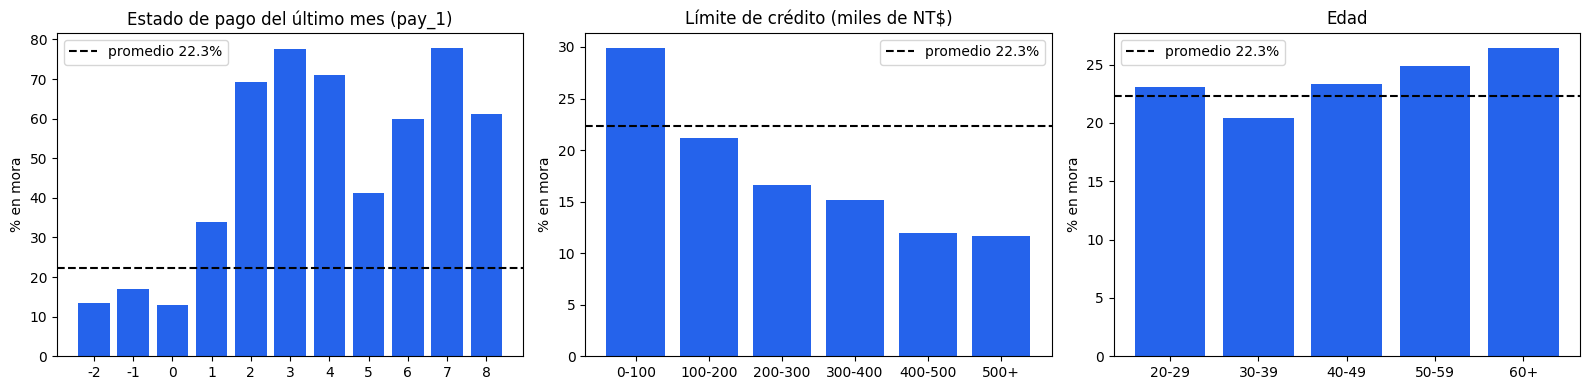

In [0]:
base_rate = train_df.agg(F.avg("default_next_month")).first()[0] * 100
groups = [
    ("Estado de pago del último mes (pay_1)", F.col("pay_1"), lambda v: str(v)),
    ("Límite de crédito (miles de NT$)", F.least(F.floor(F.col("limit_bal") / 100000), F.lit(5)) * 100,
     lambda v: f"{v}-{v + 100}" if v < 500 else "500+"),
    ("Edad", F.least(F.floor(F.col("age") / 10), F.lit(6)) * 10, lambda v: f"{v}-{v + 9}" if v < 60 else "60+"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (title, expr, label) in zip(axes, groups):
    g = (train_df.withColumn("grupo", expr.cast("int")).groupBy("grupo")
         .agg(F.avg("default_next_month").alias("tasa"), F.count("*").alias("clientes"))
         .orderBy("grupo").toPandas())
    ax.bar([label(v) for v in g["grupo"]], g["tasa"] * 100, color="#2563eb")
    ax.axhline(base_rate, color="black", ls="--", label=f"promedio {base_rate:.1f}%")
    ax.set_title(title)
    ax.set_ylabel("% en mora")
    ax.legend()
fig.tight_layout()
plt.show()